<a href="https://colab.research.google.com/github/emmanresu/Thesis-Keras/blob/latest%2Funstable/rice_stocks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from datetime import datetime

np.set_printoptions(legacy='1.25')

## Data - testing

In [ ]:
rice_stocks = 'rice_test.csv'
rice = pd.read_csv(rice_stocks)

rice

,Unnamed: 0,Unnamed: 1,January,February,March,April,May,June,July,August,September,October,November,December
0,Rice: Total Stock,2000,2364500.0,2042300.0,1765700.0,1874900.0,2067000.0,1835900.0,1628600.0,1373800.0,1195000.0,1485100.0,2010800.00,2277600.00
1,NaN,2001,2166100.0,1879400.0,1837800.0,2110700.0,2263300.0,2248000.0,2034900.0,1851300.0,1719300.0,1872600.0,2594400.00,2598000.00
2,NaN,2002,2270700.0,1975200.0,1808200.0,1997200.0,2113200.0,1788900.0,1534700.0,1313400.0,1193100.0,1508200.0,2575000.00,2676000.00
3,NaN,2003,2448100.0,2289500.0,2068500.0,2210300.0,2390800.0,2097600.0,1806100.0,1566500.0,1399600.0,1742400.0,2525000.00,2607000.00
4,NaN,2004,2362100.0,2068000.0,1857700.0,2147400.0,2338700.0,1880100.0,1577400.0,1340800.0,1189100.0,1559500.0,2289800.00,2404500.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,NaN,2021,352523.0,302482.0,265320.0,241170.9,241126.0,225087.0,205820.0,178842.0,151170.0,166342.0,244323.00,249713.00
100,NaN,2022,208328.0,181232.0,155870.0,135872.0,158803.0,175486.0,160497.0,134609.0,112382.0,111042.0,120480.00,125300.00
101,NaN,2023,114910.0,104790.0,103072.0,99033.0,100117.0,85102.0,60844.0,50948.0,43636.0,44240.0,60230.00,57130.00
102,NaN,2024,48676.0,46890.3,41285.0,41559.0,69350.0,138273.0,147199.0,150739.0,151156.0,172644.0,141677.67,144047.67


In [ ]:
for i in range(len(rice.columns)):
  if rice.columns[i]
  datetime.strptime(rice.columns[i], '%B')

Index(['Unnamed: 0', 'Unnamed: 1', 'January', 'February', 'March', 'April',
       'May', 'June', 'July', 'August', 'September', 'October', 'November',
       'December'],
      dtype='object')

In [ ]:
months = set(rice.columns[2::])
months

{'April',
 'August',
 'December',
 'February',
 'January',
 'July',
 'June',
 'March',
 'May',
 'November',
 'October',
 'September'}

In [ ]:

datetime.strptime(rice.columns[2], '%B')
i = 0
rice.columns[i]
isinstance(rice.columns[0], str)

True

In [ ]:
for i in range(len(rice.index)):
  for j in range(len(rice.columns)):
    if rice.columns[j] in months:
      month = datetime.strptime((rice.columns[j], '%B'), datetime).strftime('%m')
      print(month, rice.iloc[i, j])
    else:
      print(rice.iloc[i, j])


Rice: Total Stock
2000


TypeError: strptime() argument 1 must be str, not tuple

## Functions for processing data

In [3]:
# match columns of rice stocks and rice prices

def combine(inv, prc):
  curr_price = 0
  pointer = 0

  data = []

  for i in range(len(inv)):
    if pointer == len(prc):
      pointer = len(prc) - 1

    curr_price = prc.iloc[pointer]['price']
    prev = prc.iloc[pointer - 1]['price']

    if inv.iloc[i]['date'] == prc.iloc[pointer]['date']:
      data.append(curr_price)
      pointer += 1
    elif inv.iloc[i]['date'] < prc.iloc[pointer - 1]['date']:
      data.append(prev)
    else:
      data.append(curr_price)

  return data

In [4]:
def add_month(data):
  new_data = []
  mon_len = 0
  month = 1

  while(len(data) > mon_len):
      input = datetime.strptime(str(month), "%m")
      input = input.strftime("%m")
      new_data.append(input)
      mon_len += 1
      month += 1

      if month == 13:
          month = 1

  return new_data

In [5]:
# transforms the tabular data into a time series

def timeseries(data, drop_col):

  new_data = []

  for i in data.index:
    for j in data.columns:

      if j != None:
        year_month_str = f"{i}-{j}"
        year_month_obj = datetime.strptime(year_month_str, '%Y-%B')
        year_month = year_month_obj.strftime('%Y-%m')

        month_obj = datetime.strptime(j, '%B')
        month = month_obj.strftime('%m')

        new_data.append([year_month, month, float(data.at[i, j])])
      else:
        break

  if drop_col != None:
    new_data = np.delete(new_data, drop_col, axis=1)

  return new_data

In [61]:
'''
Add categorical values 'is_lean_month'
0 if not a lean month, 1 if in lean month
Lean months are July (07), August (08), and September (09)
'''

# def add_lean_months(dataset):
#   lean = set([7, 8, 9])
#   dataset['is_lean_month'] = np.where(pd.to_datetime(dataset['date']).dt.month.isin(lean), '1', '0')
#   return dataset

def add_lean_months(dataset):
  lean = set([7, 8, 9])
  dataset['is_lean_month'] = np.where(dataset.index.month.isin(lean), 1, 0)
  return dataset

In [7]:
testing = ["Month", "Month", "Month", "Month", "Month", "Month", "Month", "Month", "Month", "Month", "Month", "Month", "Month", "Month"]

n_data = add_month(testing)
print(n_data)

['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '01', '02']


## New dataset

In [ ]:
total_stock = 'total_stock.csv'
stock_household = 'household_stock.csv'
stock_commercial = 'commercial_stock.csv'
stock_nfa = 'nfa_stock.csv'


total = pd.read_csv(total_stock, index_col=[0])
household = pd.read_csv(stock_household, index_col=[0])
commercial = pd.read_csv(stock_commercial, index_col=[0])
nfa = pd.read_csv(stock_nfa, index_col=[0])

In [ ]:
dataset = timeseries(total, None)
hh_dataset = timeseries(household, [0, 1])
comm_dataset = timeseries(commercial, [0, 1])
nfa_dataset = timeseries(nfa, [0, 1])


dataset_df = pd.DataFrame(dataset, columns=['date', 'month', 'stock_total'])
hh_dataset_df = pd.DataFrame(hh_dataset, columns=['stock_household'])
comm_dataset_df = pd.DataFrame(comm_dataset, columns=['stock_commercial'])
nfa_dataset_df = pd.DataFrame(nfa_dataset, columns=['stock_nfa'])

dataset_df = dataset_df.join(hh_dataset_df).join(comm_dataset_df).join(nfa_dataset_df)

dataset_df

,date,month,stock_total,stock_household,stock_commercial,stock_nfa
0,2000-01,01,2364500.00,1149700.0,488200.0,726600.0
1,2000-02,02,2042300.00,1009500.0,420600.0,612200.0
2,2000-03,03,1765700.00,832200.0,381000.0,552500.0
3,2000-04,04,1874900.00,954400.0,441200.0,479300.0
4,2000-05,05,2067000.00,1059500.0,509600.0,497900.0
...,...,...,...,...,...,...
307,2025-08,08,2321437.85,837944.33,1030751.52,452742.0
308,2025-09,09,2072433.22,808431.85,815346.38,448655.0
309,2025-10,10,2354896.32,952087.39,954908.93,447900.0
310,2025-11,11,2554138.42,1149260.99,944142.43,460735.0


### Wholesale Prices

In [ ]:
prices = 'prices_ws_2000-2024.csv'
prices_wholesale = pd.read_csv(prices, index_col=[0])

prices_wholesale = prices_wholesale.iloc[1:]

prices_wholesale = prices_wholesale.reset_index()
prices_wholesale.columns = prices_wholesale.iloc[0]
prices_wholesale = prices_wholesale.drop(index=0)

prices_wholesale.reset_index(inplace=True, drop=True)
prices_wholesale = prices_wholesale.drop(index=[300, 301])

In [ ]:
prices_2025 = 'prices_ws_2025.csv'
prices_ws_2025 = pd.read_csv(prices_2025, index_col=[0])

prices_ws_2025 = prices_ws_2025.iloc[1:]

prices_ws_2025 = prices_ws_2025.reset_index()
prices_ws_2025.columns = prices_ws_2025.iloc[0]
prices_ws_2025 = prices_ws_2025.drop(index=0)

prices_ws_2025.reset_index(inplace=True, drop=True)

In [ ]:
added_month = add_month(prices_wholesale)

prices_wholesale['month'] = added_month
prices_wholesale['date'] = prices_wholesale['Year'] + "-" + prices_wholesale['month']

In [ ]:
prices_wholesale = prices_wholesale[['date', 'Regular', 'Milled']]
prices_wholesale = prices_wholesale.rename(columns={'Regular' : 'price_regular', 'Milled' : 'price_milled'})
prices_wholesale

,date,price_regular,price_milled
0,2000-01,15.65,17.38
1,2000-02,15.83,17.57
2,2000-03,15.98,17.64
3,2000-04,16.05,17.62
4,2000-05,16.29,17.75
...,...,...,...
295,2024-08,46.34,49.84
296,2024-09,45.62,49.25
297,2024-10,44.79,48.47
298,2024-11,43.89,47.75


In [ ]:
added_month_2025 = add_month(prices_ws_2025)

prices_ws_2025['month'] = added_month_2025
prices_ws_2025['date'] = prices_ws_2025['Year'] + "-" + prices_ws_2025['month']

In [ ]:
prices_ws_2025 = prices_ws_2025[['date', 'Regular', 'Milled']]
prices_ws_2025 = prices_ws_2025.rename(columns={'Regular' : 'price_regular',
                                                'Milled' : 'price_milled'})
prices_ws_2025

,date,price_regular,price_milled
0,2025-01,42.66,46.91
1,2025-02,41.32,45.79
2,2025-03,39.86,44.46
3,2025-04,38.33,42.94
4,2025-05,37.13,41.62
5,2025-06,36.5,40.97
6,2025-07,35.44,40.05
7,2025-08,35.23,39.69
8,2025-09,35.14,39.61
9,2025-10,34.68,39.48


In [ ]:
prices_wholesale = pd.concat([prices_wholesale, prices_ws_2025], ignore_index=True)
prices_wholesale = prices_wholesale.rename(columns={'price_regular' : 'regular_wholesale_price',
                                                'price_milled' : 'milled_wholesale_price'})
prices_wholesale

,date,regular_wholesale_price,milled_wholesale_price
0,2000-01,15.65,17.38
1,2000-02,15.83,17.57
2,2000-03,15.98,17.64
3,2000-04,16.05,17.62
4,2000-05,16.29,17.75
...,...,...,...
307,2025-08,35.23,39.69
308,2025-09,35.14,39.61
309,2025-10,34.68,39.48
310,2025-11,35.65,40.28


In [ ]:
dataset_df = pd.merge(dataset_df, prices_wholesale, on='date', how='inner')
dataset_df

,date,month,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price
0,2000-01,01,2364500.00,1149700.0,488200.0,726600.0,15.65,17.38
1,2000-02,02,2042300.00,1009500.0,420600.0,612200.0,15.83,17.57
2,2000-03,03,1765700.00,832200.0,381000.0,552500.0,15.98,17.64
3,2000-04,04,1874900.00,954400.0,441200.0,479300.0,16.05,17.62
4,2000-05,05,2067000.00,1059500.0,509600.0,497900.0,16.29,17.75
...,...,...,...,...,...,...,...,...
307,2025-08,08,2321437.85,837944.33,1030751.52,452742.0,35.23,39.69
308,2025-09,09,2072433.22,808431.85,815346.38,448655.0,35.14,39.61
309,2025-10,10,2354896.32,952087.39,954908.93,447900.0,34.68,39.48
310,2025-11,11,2554138.42,1149260.99,944142.43,460735.0,35.65,40.28


### Retail prices

In [ ]:
prices_r = 'prices_r_2000-2024.csv'
prices_retail = pd.read_csv(prices_r, index_col=[0])

prices_retail = prices_retail.iloc[1:]

prices_retail = prices_retail.reset_index()
prices_retail.columns = prices_retail.iloc[0]
prices_retail = prices_retail.drop(index=0)

prices_retail.reset_index(inplace=True, drop=True)
prices_retail = prices_retail.drop(index=[300, 301])

In [ ]:
prices_r_2025 = 'prices_r_2025.csv'
prices_r_2025 = pd.read_csv(prices_r_2025, index_col=[0])

prices_r_2025 = prices_r_2025.iloc[1:]

prices_r_2025 = prices_r_2025.reset_index()
prices_r_2025.columns = prices_r_2025.iloc[0]
prices_r_2025 = prices_r_2025.drop(index=0)

prices_r_2025.reset_index(inplace=True, drop=True)

In [ ]:
added_month_retail = add_month(prices_retail)

prices_retail['month'] = added_month_retail
prices_retail['date'] = prices_retail['Year'] + "-" + prices_retail['month']

In [ ]:
prices_retail = prices_retail[['date', 'Regular', 'Milled']]
prices_retail = prices_retail.rename(columns={'Regular' : 'price_regular', 'Milled' : 'price_milled'})
prices_retail

,date,price_regular,price_milled
0,2000-01,17.05,19
1,2000-02,17.2,19.12
2,2000-03,17.32,19.22
3,2000-04,17.38,19.21
4,2000-05,17.45,19.27
...,...,...,...
295,2024-08,50.66,55.56
296,2024-09,50.47,55.51
297,2024-10,50.22,55.28
298,2024-11,49.24,54.64


In [ ]:
added_month_retail_2025 = add_month(prices_r_2025)

prices_r_2025['month'] = added_month_retail_2025
prices_r_2025['date'] = prices_r_2025['Year'] + "-" + prices_r_2025['month']

In [ ]:
prices_r_2025 = prices_r_2025[['date', 'Regular', 'Milled']]
prices_r_2025 = prices_r_2025.rename(columns={'Regular' : 'price_regular',
                                                'Milled' : 'price_milled'})
prices_r_2025

,date,price_regular,price_milled
0,2025-01,48.25,54.14
1,2025-02,47.23,53.46
2,2025-03,46.09,52.25
3,2025-04,44.45,50.54
4,2025-05,43.19,49.45
5,2025-06,42.35,48.47
6,2025-07,41.31,47.6
7,2025-08,40.43,46.51
8,2025-09,40.23,46.5
9,2025-10,40.09,46.49


In [ ]:
prices_retail = pd.concat([prices_retail, prices_r_2025], ignore_index=True)
prices_retail = prices_retail.rename(columns={'price_regular' : 'regular_retail_price',
                                                'price_milled' : 'milled_retail_price'})
prices_retail

,date,regular_retail_price,milled_retail_price
0,2000-01,17.05,19
1,2000-02,17.2,19.12
2,2000-03,17.32,19.22
3,2000-04,17.38,19.21
4,2000-05,17.45,19.27
...,...,...,...
307,2025-08,40.43,46.51
308,2025-09,40.23,46.5
309,2025-10,40.09,46.49
310,2025-11,40.29,46.8


In [ ]:
dataset_df = pd.merge(dataset_df, prices_retail, on='date', how='inner')
dataset_df

,date,month,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price
0,2000-01,01,2364500.00,1149700.0,488200.0,726600.0,15.65,17.38,17.05,19
1,2000-02,02,2042300.00,1009500.0,420600.0,612200.0,15.83,17.57,17.2,19.12
2,2000-03,03,1765700.00,832200.0,381000.0,552500.0,15.98,17.64,17.32,19.22
3,2000-04,04,1874900.00,954400.0,441200.0,479300.0,16.05,17.62,17.38,19.21
4,2000-05,05,2067000.00,1059500.0,509600.0,497900.0,16.29,17.75,17.45,19.27
...,...,...,...,...,...,...,...,...,...,...
307,2025-08,08,2321437.85,837944.33,1030751.52,452742.0,35.23,39.69,40.43,46.51
308,2025-09,09,2072433.22,808431.85,815346.38,448655.0,35.14,39.61,40.23,46.5
309,2025-10,10,2354896.32,952087.39,954908.93,447900.0,34.68,39.48,40.09,46.49
310,2025-11,11,2554138.42,1149260.99,944142.43,460735.0,35.65,40.28,40.29,46.8


### Lean months

In [ ]:
# Input binary data: 1 if lean month, 0 if not

dataset_df = add_lean_months(dataset_df)
dataset_df

,date,month,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,is_lean_month
0,2000-01,01,2364500.00,1149700.0,488200.0,726600.0,15.65,17.38,17.05,19,0
1,2000-02,02,2042300.00,1009500.0,420600.0,612200.0,15.83,17.57,17.2,19.12,0
2,2000-03,03,1765700.00,832200.0,381000.0,552500.0,15.98,17.64,17.32,19.22,0
3,2000-04,04,1874900.00,954400.0,441200.0,479300.0,16.05,17.62,17.38,19.21,0
4,2000-05,05,2067000.00,1059500.0,509600.0,497900.0,16.29,17.75,17.45,19.27,0
...,...,...,...,...,...,...,...,...,...,...,...
307,2025-08,08,2321437.85,837944.33,1030751.52,452742.0,35.23,39.69,40.43,46.51,1
308,2025-09,09,2072433.22,808431.85,815346.38,448655.0,35.14,39.61,40.23,46.5,1
309,2025-10,10,2354896.32,952087.39,954908.93,447900.0,34.68,39.48,40.09,46.49,0
310,2025-11,11,2554138.42,1149260.99,944142.43,460735.0,35.65,40.28,40.29,46.8,0


In [ ]:
dataset_df

,date,month,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,is_lean_month
0,2000-01,01,2364500.00,1149700.0,488200.0,726600.0,15.65,17.38,17.05,19,0
1,2000-02,02,2042300.00,1009500.0,420600.0,612200.0,15.83,17.57,17.2,19.12,0
2,2000-03,03,1765700.00,832200.0,381000.0,552500.0,15.98,17.64,17.32,19.22,0
3,2000-04,04,1874900.00,954400.0,441200.0,479300.0,16.05,17.62,17.38,19.21,0
4,2000-05,05,2067000.00,1059500.0,509600.0,497900.0,16.29,17.75,17.45,19.27,0
...,...,...,...,...,...,...,...,...,...,...,...
307,2025-08,08,2321437.85,837944.33,1030751.52,452742.0,35.23,39.69,40.43,46.51,1
308,2025-09,09,2072433.22,808431.85,815346.38,448655.0,35.14,39.61,40.23,46.5,1
309,2025-10,10,2354896.32,952087.39,954908.93,447900.0,34.68,39.48,40.09,46.49,0
310,2025-11,11,2554138.42,1149260.99,944142.43,460735.0,35.65,40.28,40.29,46.8,0


### Save dataset

In [ ]:
dataset_df.to_csv('dataset.csv')

## Additional entries

In [ ]:
total_stock = 'total_stock_2026.csv'
stock_household = 'household_stock_2026.csv'
stock_commercial = 'commercial_stock_2026.csv'
stock_nfa = 'nfa_stock_2026.csv'

total = pd.read_csv(total_stock, index_col=[0])
household = pd.read_csv(stock_household, index_col=[0])
commercial = pd.read_csv(stock_commercial, index_col=[0])
nfa = pd.read_csv(stock_nfa, index_col=[0])

In [ ]:
data_additional = timeseries(total, None)
hh_dataset = timeseries(household, [0, 1])
comm_dataset = timeseries(commercial, [0, 1])
nfa_dataset = timeseries(nfa, [0, 1])

data_additional = pd.DataFrame(data_additional, columns=['date', 'month', 'stock_total'])
hh_dataset_df = pd.DataFrame(hh_dataset, columns=['stock_household'])
comm_dataset_df = pd.DataFrame(comm_dataset, columns=['stock_commercial'])
nfa_dataset_df = pd.DataFrame(nfa_dataset, columns=['stock_nfa'])

data_additional = data_additional.join(hh_dataset_df).join(comm_dataset_df).join(nfa_dataset_df)

data_additional

,date,month,stock_total,stock_household,stock_commercial,stock_nfa
0,2026-01,01,2341155.06,1043525.46,858877.0,438752.6
1,2026-02,02,2112282.15,899568.63,791200.85,421512.67
2,2026-03,03,1877328.88,908721.92,564220.75,404386.21


In [ ]:
rice_prices_2026 = 'rice_prices_2026.csv'
prices = pd.read_csv(rice_prices_2026, index_col=[0])
prices = prices.reset_index()
prices = pd.DataFrame(prices, columns=['date', 'regular_wholesale_price', 'milled_wholesale_price',
                                       'regular_retail_price', 'milled_retail_price'])
prices

,date,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price
0,2026-01,39.81,45.16,43.29,50.05
1,2026-02,41.60,47.72,45.27,52.21
2,2026-03,44.71,50.06,47.72,54.88


In [ ]:
data_additional = pd.merge(data_additional, prices, on='date', how='inner')
data_additional

,date,month,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price
0,2026-01,01,2341155.06,1043525.46,858877.0,438752.6,39.81,45.16,43.29,50.05
1,2026-02,02,2112282.15,899568.63,791200.85,421512.67,41.60,47.72,45.27,52.21
2,2026-03,03,1877328.88,908721.92,564220.75,404386.21,44.71,50.06,47.72,54.88


In [ ]:
dataset_df = pd.concat([dataset_df, data_additional], ignore_index=True)
add_lean_months(dataset_df)
print(dataset_df.to_string())

        date month  stock_total stock_household stock_commercial  stock_nfa  regular_wholesale_price  milled_wholesale_price  regular_retail_price  milled_retail_price is_lean_month
0    2000-01     1   2364500.00       1149700.0         488200.0   726600.0                    15.65                   17.38                 17.05                19.00             0
1    2000-02     2   2042300.00       1009500.0         420600.0   612200.0                    15.83                   17.57                 17.20                19.12             0
2    2000-03     3   1765700.00        832200.0         381000.0   552500.0                    15.98                   17.64                 17.32                19.22             0
3    2000-04     4   1874900.00        954400.0         441200.0   479300.0                    16.05                   17.62                 17.38                19.21             0
4    2000-05     5   2067000.00       1059500.0         509600.0   497900.0               

In [ ]:
dataset_df.to_csv('dataset.csv')

## Load dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

np.set_printoptions(legacy='1.25')

In [2]:
data = 'dataset.csv'
data = pd.read_csv(data, index_col=[0])
data.index = pd.to_datetime(data['date']).dt.to_period('M')
data = data.drop(columns=['month'])
data

,date,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,is_lean_month
date,,,,,,,,,,
2000-01,2000-01,2364500.00,1149700.00,488200.00,726600.00,15.65,17.38,17.05,19.00,0
2000-02,2000-02,2042300.00,1009500.00,420600.00,612200.00,15.83,17.57,17.20,19.12,0
2000-03,2000-03,1765700.00,832200.00,381000.00,552500.00,15.98,17.64,17.32,19.22,0
2000-04,2000-04,1874900.00,954400.00,441200.00,479300.00,16.05,17.62,17.38,19.21,0
2000-05,2000-05,2067000.00,1059500.00,509600.00,497900.00,16.29,17.75,17.45,19.27,0
...,...,...,...,...,...,...,...,...,...,...
2025-11,2025-11,2554138.42,1149260.99,944142.43,460735.00,35.65,40.28,40.29,46.80,0
2025-12,2025-12,2704507.01,1026400.66,1221968.35,456138.00,37.83,42.94,41.49,48.25,0
2026-01,2026-01,2341155.06,1043525.46,858877.00,438752.60,39.81,45.16,43.29,50.05,0


### Shift features by N months

In [8]:
def shift_features(data, months_shift):
  data_shift = data.drop(columns=['stock_total', 'is_lean_month'])
  data_shift.index = pd.to_datetime(data['date']).dt.to_period('M')
  data_shift = data_shift.drop(columns=['date'])

  data_shift = data_shift.shift(periods=months_shift, freq="infer")
  stock_total = data[['date', 'stock_total']]
  stock_total.index = pd.to_datetime(stock_total['date']).dt.to_period('M')
  stock_total = stock_total.drop(columns=['date'])

  data_shift = pd.concat([stock_total, data_shift], axis=1)

  data_shift = data_shift[months_shift:]

  data_shift, remaining_features = data_shift[0:-12], data_shift[-12:]

  return data_shift, remaining_features

def whole_data(data):
  with pd.option_context('display.max_rows', None, 'display.max_columns', None):  # more options can be specified also
      print(data)

### features shift 6 months

In [ ]:
total_stock, remaining_features = shift_features(data, 6)

         stock_total  stock_household  stock_commercial   stock_nfa  \
date                                                                  
2000-07   1628600.00       1149700.00         488200.00   726600.00   
2000-08   1373800.00       1009500.00         420600.00   612200.00   
2000-09   1195000.00        832200.00         381000.00   552500.00   
2000-10   1485100.00        954400.00         441200.00   479300.00   
2000-11   2010800.00       1059500.00         509600.00   497900.00   
2000-12   2277600.00        800300.00         485500.00   550100.00   
2001-01   2166100.00        665500.00         456800.00   506300.00   
2001-02   1879400.00        551900.00         360000.00   461900.00   
2001-03   1837800.00        510600.00         326400.00   358000.00   
2001-04   2110700.00        730400.00         410800.00   343900.00   
2001-05   2263300.00       1197600.00         410300.00   402900.00   
2001-06   2248000.00       1337900.00         471900.00   467800.00   
2001-0

### features shift 12 months

In [9]:
total_stock, remaining_features = shift_features(data, 12)

### Final dataset

In [18]:
total_stock, remaining_features = add_lean_months(total_stock), add_lean_months(remaining_features)

## Check correlation

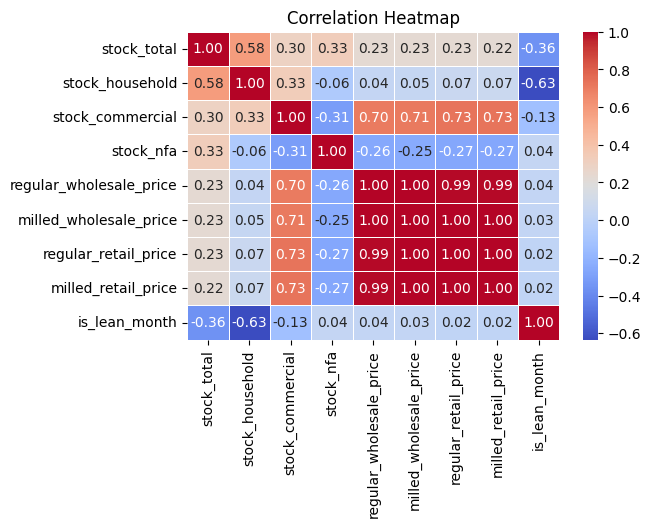

In [11]:
import seaborn as sns

# Calculate correlation matrix
corr_matrix = total_stock[['stock_total', 'stock_household', 'stock_commercial',
                          'stock_nfa', 'regular_wholesale_price', 'milled_wholesale_price',
                          'regular_retail_price', 'milled_retail_price', 'is_lean_month']].corr()

# Create the plot
plt.figure(figsize=(6,  4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show('correlation_plot.png')
# print("correlation_plot.png saved")

## Model Training (not used)

In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from xgboost import XGBRegressor

# 1. FIT HOLT-WINTERS (Univariate)
# We only use the 'target' column here
hw_model = ExponentialSmoothing(data['stock_total'], trend='add', seasonal='add', seasonal_periods=12).fit()
data['hw_basis'] = hw_model.fittedvalues

In [ ]:
data

,date,stock_total,stock_household,stock_commercial,stock_nfa,price_regular,price_milled,is_lean_month,stock_commerical,hw_basis
0,2000-01,2364500.00,1149700.00,488200.00,726600.0,15.65,17.38,0,488200.00,2.184590e+06
1,2000-02,2042300.00,1009500.00,420600.00,612200.0,15.83,17.57,0,420600.00,2.121176e+06
2,2000-03,1765700.00,832200.00,381000.00,552500.0,15.98,17.64,0,381000.00,1.936581e+06
3,2000-04,1874900.00,954400.00,441200.00,479300.0,16.05,17.62,0,441200.00,2.098021e+06
4,2000-05,2067000.00,1059500.00,509600.00,497900.0,16.29,17.75,0,509600.00,2.066639e+06
...,...,...,...,...,...,...,...,...,...,...
307,2025-08,2321437.85,837944.33,1030751.52,452742.0,35.23,39.69,1,1030751.52,2.229756e+06
308,2025-09,2072433.22,808431.85,815346.38,448655.0,35.14,39.61,1,815346.38,2.089261e+06
309,2025-10,2354896.32,952087.39,954908.93,447900.0,34.68,39.48,0,954908.93,2.607736e+06
310,2025-11,2554138.42,1149260.99,944142.43,460735.0,35.65,40.28,0,944142.43,2.881995e+06


In [ ]:
# 2. CALCULATE RESIDUALS
# This is what XGBoost will try to solve
data['residuals'] = data['stock_total'] - data['hw_basis']
data

,date,stock_total,stock_household,stock_commercial,stock_nfa,price_regular,price_milled,is_lean_month,stock_commerical,hw_basis,residuals
0,2000-01,2364500.00,1149700.00,488200.00,726600.0,15.65,17.38,0,488200.00,2.184590e+06,179909.819425
1,2000-02,2042300.00,1009500.00,420600.00,612200.0,15.83,17.57,0,420600.00,2.121176e+06,-78876.380520
2,2000-03,1765700.00,832200.00,381000.00,552500.0,15.98,17.64,0,381000.00,1.936581e+06,-170881.451121
3,2000-04,1874900.00,954400.00,441200.00,479300.0,16.05,17.62,0,441200.00,2.098021e+06,-223120.858609
4,2000-05,2067000.00,1059500.00,509600.00,497900.0,16.29,17.75,0,509600.00,2.066639e+06,360.555677
...,...,...,...,...,...,...,...,...,...,...,...
307,2025-08,2321437.85,837944.33,1030751.52,452742.0,35.23,39.69,1,1030751.52,2.229756e+06,91682.075134
308,2025-09,2072433.22,808431.85,815346.38,448655.0,35.14,39.61,1,815346.38,2.089261e+06,-16827.552357
309,2025-10,2354896.32,952087.39,954908.93,447900.0,34.68,39.48,0,954908.93,2.607736e+06,-252839.707633
310,2025-11,2554138.42,1149260.99,944142.43,460735.0,35.65,40.28,0,944142.43,2.881995e+06,-327856.781383


In [ ]:
# 3. TRAIN XGBOOST ON FEATURES
# Features (X) can be anything: price, promo, weather, etc.
X = data[['stock_commercial', 'stock_household', 'stock_nfa', 'price_regular',
          'price_milled', 'is_lean_month', 'hw_basis']]
y = data['residuals']

xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.05, enable_categorical=True)
xgb_model.fit(X, y)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
# 4. PREDICT & RECOMPOSE
# Final Forecast = HW Prediction + XGBoost's correction
hw_future = hw_model.forecast(steps=12)
xgb_correction = xgb_model.predict(X_future)

final_forecast = hw_future + xgb_correction


NameError: name 'X_future' is not defined

### Dataset split and cross validation


In [ ]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error

In [ ]:
# 2. Initialize TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=8)
rmse_scores = []

In [ ]:
print(f"{'Fold':<10} | {'Train Size':<12} | {'Test Size':<10} | {'RMSE'}")
print("-" * 50)
for i, (train_index, test_index) in enumerate(tscv.split(data)):
    train, test = data.iloc[train_index], data.iloc[test_index]

    # 4. Fit Holt-Winters Model
    # Note: Adjust trend, seasonal, and seasonal_periods based on your data
    model = ExponentialSmoothing(
        train['stock_total'],
        trend='add',
        seasonal='add',
        seasonal_periods=12
    ).fit()
# 5. Forecast
    predictions = model.forecast(len(test))

# 6. Evaluate
    rmse = np.sqrt(mean_squared_error(test['stock_total'], predictions))
    rmse_scores.append(rmse)

    print(f"{i+1:<10} | {len(train):<12} | {len(test):<10} | {rmse:.4f}")

Fold       | Train Size   | Test Size  | RMSE
--------------------------------------------------
1          | 35           | 35         | 2763081.2278
2          | 70           | 35         | 248162.7070
3          | 105          | 35         | 539276.2944
4          | 140          | 35         | 1282441.8959
5          | 175          | 35         | 483710.1845
6          | 210          | 35         | 328878.7549
7          | 245          | 35         | 313649.4908
8          | 280          | 35         | 638305.6821


In [ ]:
print("-" * 50)
print(f"Average RMSE: {np.mean(rmse_scores):.4f}")

--------------------------------------------------
Average RMSE: 357315.6441


## SARIMA Testing

### Augmented Dickey-Fuller test

In [ ]:
pip install pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 12.1 MB/s eta 0:00:00


In [ ]:
import pmdarima as pm
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 1. Automatically determine 'd' and 'D' using ADF and other tests
d_order = pm.arima.ndiffs(data['stock_total'], test='adf')          # test = 'adf' working
D_order = pm.arima.nsdiffs(data['stock_total'], m=12, test='ocsb')  # test = 'ocsb' working

print(f"Recommended non-seasonal differencing (d): {d_order}")
print(f"Recommended seasonal differencing (D): {D_order}")

# 2. Fit the SARIMA model using those parameters
# Example order: (p, d, q) x (P, D, Q, s)
model = SARIMAX(data['stock_total'],
                order=(1, d_order, 1),
                seasonal_order=(1, D_order, 1, 12))

results = model.fit()
print(results.summary())

Recommended non-seasonal differencing (d): 0
Recommended seasonal differencing (D): 0
                                     SARIMAX Results                                      
Dep. Variable:                        stock_total   No. Observations:                  312
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 12)   Log Likelihood               -4309.584
Date:                            Sun, 19 Apr 2026   AIC                           8629.169
Time:                                    13:31:34   BIC                           8647.884
Sample:                                         0   HQIC                          8636.648
                                            - 312                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9316      0

## Holt-winters and XGBoost model


### Holt-Winters
### Time series cross-validation and Hyperparameter tuning (Expanding Window)

In [12]:
import itertools
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import r2_score

def tscv_holt_winters(data, seasonal_periods, param_grid, splits, train_each_fold):
    tscv = TimeSeriesSplit(n_splits=splits, max_train_size=train_each_fold)

    # Generate all combinations of alpha, beta, and gamma
    keys, values = zip(*param_grid.items())
    combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

    results_list = []

    for combo in combinations:
        fold_mapes = []
        fold_mae = []
        fold_rmse = []
        fold_r2 = []
        train_size = []
        test_size = []

        # Cross-validation on the train_val subset
        for train_index, test_index in tscv.split(train_val):
            train, test = train_val.iloc[train_index], train_val.iloc[test_index]

            try:
                model = ExponentialSmoothing(
                    train,
                    trend='add',
                    seasonal='add',
                    seasonal_periods=seasonal_periods
                ).fit(
                    smoothing_level=combo['alpha'],
                    smoothing_trend=combo['beta'],
                    smoothing_seasonal=combo['gamma'],
                    optimized=False
                )

                forecast = model.forecast(len(test))
                mape = mean_absolute_percentage_error(test, forecast)
                mae = mean_absolute_error(test, forecast)
                rmse = root_mean_squared_error(test, forecast)
                r2 = r2_score(test, forecast)

                fold_mae.append(mae)
                fold_rmse.append(rmse)
                fold_mapes.append(mape)
                fold_r2.append(r2)

                train_input = len(train)
                train_size.append(train_input)
                test_input = len(test)
                test_size.append(test_input)
            except Exception:
                # Handle cases where parameters lead to non-convergence
                continue

        # Store average performance and parameters for the list
        if fold_mapes:
            avg_mape = np.mean(fold_mapes)
            avg_mae = np.mean(fold_mae)
            avg_rmse = np.mean(fold_rmse)
            avg_r2 = np.mean(fold_r2)
            mape_variance = np.var(fold_mapes)
            results_list.append({
                "alpha": combo['alpha'],
                "beta": combo['beta'],
                "gamma": combo['gamma'],
                "mape_variance" : round(mape_variance, 8),
                "avg_MAPE": round((avg_mape), 4),
                "avg_MAE": round((avg_mae), 4),
                "avg_RMSE": round((avg_rmse), 4),
                "avg_R2": round((avg_r2), 4),
                "fold_details": [(tr_size, ts_size, round(mape, 4))
                  for tr_size, ts_size, mape in zip(train_size, test_size, fold_mapes)]
            })
    # return sorted(results_list, key=lambda x: x['mape_variance'])
    return results_list

In [13]:
# parameters to be tested
params = {
  'alpha': [0.1, 0.3, 0.5, 0.7, 0.9],
  'beta': [0.001, 0.01, 0.05, 0.1, 0.3, 0.5, 0.7, 0.9],
  'gamma': [0.001, 0.01, 0.05, 0.1, 0.3, 0.5, 0.7, 0.9]
}

# final model test size
holdout_size = 24
train_val = total_stock['stock_total'].iloc[:-holdout_size]

In [14]:
''''
tscv_holt_winters(1, 2, 3, 4, 5) parameters:
  1 - training set
  2 - number of seasonal period - 12(yearly) default
  3 - hyperparameters (grid)
  4 - number of folds (number of cross-validation)
  5 - number of maximum training set (set to None for expanding window approach)
'''

models_exp = tscv_holt_winters(train_val, 12, params, 5, None)
# models_rol = tscv_holt_winters(train_val, 12, params, 5, 51)

In [15]:
avg_mape_models = sorted(models_exp, key=lambda x: x['avg_MAPE'])
# sorted(models, key=lambda x: x['mape_variance'])

top_lowest_mape = [x for x in avg_mape_models[:10]]
for i in top_lowest_mape:
  print(i)

{'alpha': 0.9, 'beta': 0.01, 'gamma': 0.3, 'mape_variance': 0.00424558, 'avg_MAPE': 0.212, 'avg_MAE': 478854.4915, 'avg_RMSE': 576823.9683, 'avg_R2': -0.7531, 'fold_details': [(49, 46, 0.3014), (95, 46, 0.1482), (141, 46, 0.227), (187, 46, 0.2553), (233, 46, 0.1279)]}
{'alpha': 0.9, 'beta': 0.01, 'gamma': 0.1, 'mape_variance': 0.00457447, 'avg_MAPE': 0.221, 'avg_MAE': 496032.7288, 'avg_RMSE': 606924.5968, 'avg_R2': -0.8955, 'fold_details': [(49, 46, 0.3086), (95, 46, 0.154), (141, 46, 0.2088), (187, 46, 0.2893), (233, 46, 0.1443)]}
{'alpha': 0.7, 'beta': 0.01, 'gamma': 0.1, 'mape_variance': 0.00509914, 'avg_MAPE': 0.2245, 'avg_MAE': 504864.514, 'avg_RMSE': 613235.777, 'avg_R2': -0.9233, 'fold_details': [(49, 46, 0.3041), (95, 46, 0.1529), (141, 46, 0.2155), (187, 46, 0.3085), (233, 46, 0.1415)]}
{'alpha': 0.7, 'beta': 0.01, 'gamma': 0.3, 'mape_variance': 0.00479301, 'avg_MAPE': 0.2275, 'avg_MAE': 514220.894, 'avg_RMSE': 610312.9214, 'avg_R2': -0.9265, 'fold_details': [(49, 46, 0.301), 

### Final Holt-winters model

In [16]:
''' The parameters with the lowest average mape / mape variance across all folds is selected
for the final model.  '''
best_model_onavg = top_lowest_mape[0]
print(f"Best Parameters: level: {best_model_onavg['alpha']} | "
      f"trend: {best_model_onavg['beta']} | seasonal: {best_model_onavg['gamma']}")

# 3. Prepare the Final Datasets
holdout_size = 24
train_val = total_stock['stock_total'].iloc[:-holdout_size]
test = total_stock['stock_total'].iloc[-holdout_size:]

# 4. Train the Final Model on the entire train_val set
final_model = ExponentialSmoothing(
    train_val,
    trend='add',
    seasonal='add',
    seasonal_periods=12,
).fit(
    smoothing_level=best_model_onavg['alpha'],
    smoothing_trend=best_model_onavg['beta'],
    smoothing_seasonal=best_model_onavg['gamma'],
    optimized=False
)

# 5. Test against the Hold-out Set
final_forecast = final_model.forecast(holdout_size)
final_mape = mean_absolute_percentage_error(test, final_forecast)
final_mae = mean_absolute_error(test, final_forecast)
final_rmse = root_mean_squared_error(test, final_forecast)
final_r2 = r2_score(test, final_forecast)

print(f"Final Model MAPE: {round(final_mape, 4)}\n"
f"Final Model MAE: {round(final_mae, 4)}\n"
f"Final Model RMSE: {round(final_rmse, 4)}\n"
f"Final Model R2: {round(final_r2, 4)}")

Best Parameters: level: 0.9 | trend: 0.01 | seasonal: 0.3
Final Model MAPE: 0.2853
Final Model MAE: 632412.6832
Final Model RMSE: 702828.4062
Final Model R2: -4.6858


### Visualization: Holt-winters

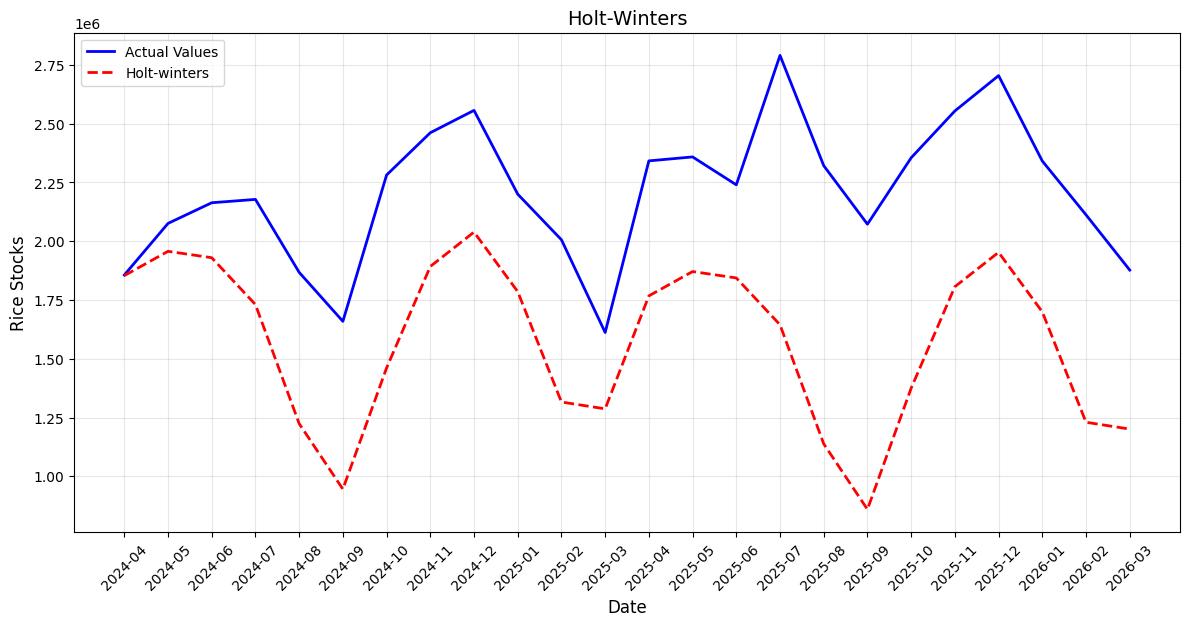

In [17]:
# 1. Formatting the date range for the legend
start_date = data['date'].iloc[-holdout_size:].min()
end_date = data['date'].iloc[-holdout_size:].max()
date_range_str = f"({start_date} to {end_date})"

# 2. Plotting
plt.figure(figsize=(12, 6))

# Actual Values
plt.plot(data['date'].iloc[-holdout_size:], test, label=f'Actual Values', color='blue', linewidth=2)

# Predicted Values
plt.plot(data['date'].iloc[-holdout_size:], final_forecast, label=f'Holt-winters', color='red', linestyle='--', linewidth=2)

# 3. Aesthetics
plt.title('Holt-Winters', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice Stocks', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(data['date'][::1].iloc[-holdout_size:], rotation=45)

plt.show()

### XGBoost

In [36]:
whole_data = pd.concat([total_stock, remaining_features], axis=0)
total_stock

,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,is_lean_month
date,,,,,,,,,
2001-01,2166100.00,1149700.00,488200.00,726600.00,15.65,17.38,17.05,19.00,0
2001-02,1879400.00,1009500.00,420600.00,612200.00,15.83,17.57,17.20,19.12,0
2001-03,1837800.00,832200.00,381000.00,552500.00,15.98,17.64,17.32,19.22,0
2001-04,2110700.00,954400.00,441200.00,479300.00,16.05,17.62,17.38,19.21,0
2001-05,2263300.00,1059500.00,509600.00,497900.00,16.29,17.75,17.45,19.27,0
...,...,...,...,...,...,...,...,...,...
2025-11,2554138.42,901206.77,1418557.09,141677.67,43.89,47.75,49.24,54.64,0
2025-12,2704507.01,898293.46,1514261.25,144047.67,43.60,47.57,48.81,54.38,0
2026-01,2341155.06,1054600.02,860797.99,284812.00,42.66,46.91,48.25,54.14,0


In [ ]:
data_shift_12

,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price
date,,,,,,,,
2001-01,2166100.0,1149700.00,488200.00,726600.00,15.65,17.38,17.05,19.00
2001-02,1879400.0,1009500.00,420600.00,612200.00,15.83,17.57,17.20,19.12
2001-03,1837800.0,832200.00,381000.00,552500.00,15.98,17.64,17.32,19.22
2001-04,2110700.0,954400.00,441200.00,479300.00,16.05,17.62,17.38,19.21
2001-05,2263300.0,1059500.00,509600.00,497900.00,16.29,17.75,17.45,19.27
...,...,...,...,...,...,...,...,...
2026-11,NaN,1149260.99,944142.43,460735.00,35.65,40.28,40.29,46.80
2026-12,NaN,1026400.66,1221968.35,456138.00,37.83,42.94,41.49,48.25
2027-01,NaN,1043525.46,858877.00,438752.60,39.81,45.16,43.29,50.05


In [37]:
data_xgb = total_stock.iloc[:-holdout_size]
data_xgb['residuals'] = data_xgb['stock_total'] - final_model.fittedvalues
data_xgb

/tmp/ipykernel_5050/2408645473.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_xgb['residuals'] = data_xgb['stock_total'] - final_model.fittedvalues


,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,is_lean_month,residuals
date,,,,,,,,,,
2001-01,2166100.00,1149700.00,488200.00,726600.0,15.65,17.38,17.05,19.00,0,-301590.946970
2001-02,1879400.00,1009500.00,420600.00,612200.0,15.83,17.57,17.20,19.12,0,-43836.348144
2001-03,1837800.00,832200.00,381000.00,552500.0,15.98,17.64,17.32,19.22,0,201881.555539
2001-04,2110700.00,954400.00,441200.00,479300.0,16.05,17.62,17.38,19.21,0,82902.036907
2001-05,2263300.00,1059500.00,509600.00,497900.0,16.29,17.75,17.45,19.27,0,-7464.949955
...,...,...,...,...,...,...,...,...,...,...
2023-11,1978558.36,1491320.00,1038010.00,120480.0,34.88,38.09,39.57,43.86,0,-658519.250931
2023-12,1895782.56,1476280.00,933010.00,125300.0,35.04,38.19,39.63,43.98,0,-137129.818952
2024-01,2027180.48,1083610.00,651930.00,114910.0,35.11,38.28,39.59,43.92,0,592525.776703


In [ ]:
'''
NOT USED
# data_xgb = data_xgb.drop(columns=['stock_total']) # only include for standalone xgb
data_xgb_add_12_feat = data_xgb[-12:]
data_xgb = data_xgb[:-12]

with pd.option_context('display.max_rows', None, 'display.max_columns', None):  # more options can be specified also
    print(data_xgb[-24:])
'''

         stock_total  stock_household  stock_commercial  stock_nfa  \
date                                                                 
2022-04   2506130.00       1464978.00         738160.00   241170.9   
2022-05   2279957.29       1425103.00         918668.35   241126.0   
2022-06   2090620.07       1132455.00        1173281.49   225087.0   
2022-07   2034574.68        985551.00         986310.00   205820.0   
2022-08   1633359.30        751071.00         648399.23   178842.0   
2022-09   1450885.19        638163.00         543023.90   151170.0   
2022-10   2081839.99       1059684.00         728694.67   166342.0   
2022-11   2649810.00       1332368.00         841738.07   244323.0   
2022-12   2534590.00       1296967.60         831165.69   249713.0   
2023-01   1850450.00        991556.00         659563.81   208328.0   
2023-02   1523032.91        882743.00         545273.25   181232.0   
2023-03   1408846.11        864920.00         611330.00   155870.0   
2023-04   1843053.31

In [38]:
data_xgb

,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,is_lean_month,residuals
date,,,,,,,,,,
2001-01,2166100.00,1149700.00,488200.00,726600.0,15.65,17.38,17.05,19.00,0,-301590.946970
2001-02,1879400.00,1009500.00,420600.00,612200.0,15.83,17.57,17.20,19.12,0,-43836.348144
2001-03,1837800.00,832200.00,381000.00,552500.0,15.98,17.64,17.32,19.22,0,201881.555539
2001-04,2110700.00,954400.00,441200.00,479300.0,16.05,17.62,17.38,19.21,0,82902.036907
2001-05,2263300.00,1059500.00,509600.00,497900.0,16.29,17.75,17.45,19.27,0,-7464.949955
...,...,...,...,...,...,...,...,...,...,...
2023-11,1978558.36,1491320.00,1038010.00,120480.0,34.88,38.09,39.57,43.86,0,-658519.250931
2023-12,1895782.56,1476280.00,933010.00,125300.0,35.04,38.19,39.63,43.98,0,-137129.818952
2024-01,2027180.48,1083610.00,651930.00,114910.0,35.11,38.28,39.59,43.92,0,592525.776703


### Correlation matrix residuals feature included

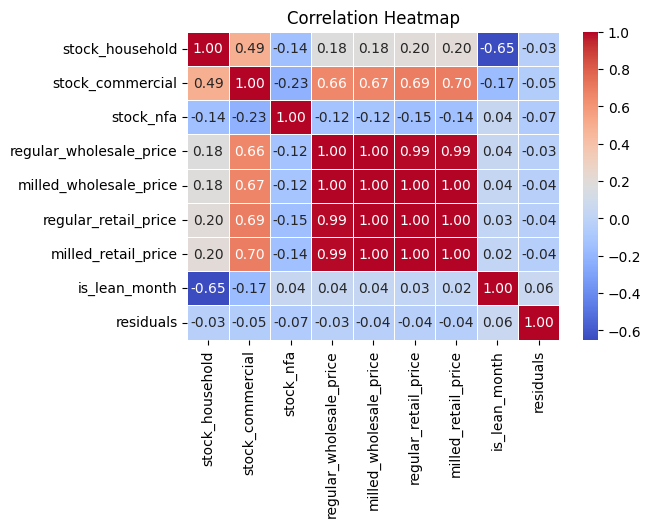

In [40]:
# Calculate correlation matrix
corr_matrix_resid = data_xgb[['stock_household', 'stock_commercial',
                          'stock_nfa', 'regular_wholesale_price', 'milled_wholesale_price',
                          'regular_retail_price', 'milled_retail_price', 'is_lean_month', 'residuals']].corr()

# Create the plot
plt.figure(figsize=(6,  4))
sns.heatmap(corr_matrix_resid, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show('correlation_plot.png')

### experiment 1: x - features, y - residuals

In [70]:
X_train = data_xgb.drop(columns=['stock_total', 'residuals'])
y_train = data_xgb['residuals']

X_train['stock_commercial'] = X_train['stock_commercial'].astype('float64')
X_train['stock_household'] = X_train['stock_household'].astype('float64')
X_train['stock_nfa'] = X_train['stock_nfa'].astype('float64')
X_train['regular_wholesale_price'] = X_train['regular_wholesale_price'].astype('float64')
X_train['milled_wholesale_price'] = X_train['milled_wholesale_price'].astype('float64')
X_train['regular_retail_price'] = X_train['regular_retail_price'].astype('float64')
X_train['milled_retail_price'] = X_train['milled_retail_price'].astype('float64')
X_train['is_lean_month'] = X_train['is_lean_month'].astype('int')
# y_train['residuals'] = y_train['residuals'].astype('float64')

# print(X_train['stock_total'].dtype)
print(X_train['stock_commercial'].dtype)
print(X_train['stock_household'].dtype)
print(X_train['stock_nfa'].dtype)
print(X_train['regular_wholesale_price'].dtype)
print(X_train['milled_wholesale_price'].dtype)
print(X_train['regular_retail_price'].dtype)
print(X_train['milled_retail_price'].dtype)
print(X_train['is_lean_month'].dtype)
print(y_train.dtype)

float64
float64
float64
float64
float64
float64
float64
int64
float64


### experiment 2: x - features, y - stock_total

In [ ]:
X_train = data_xgb.drop(columns=['date', 'stock_total', 'month'])
y_train = data_xgb['stock_total']

In [ ]:
X_train = X_train.drop(columns=['month'])
X_train

KeyError: "['month'] not found in axis"

### XGBoost training - Hybrid

In [49]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV

xgb_reg = XGBRegressor(objective='reg:squarederror', random_state=42,
                       enable_categorical=True, early_stopping=True)

# Define Parameter Grid
'''
    default parameters:
    param_grid = {
      'n_estimators': [100, 300, 500],
      'max_depth': [3, 5, 7],
      'learning_rate': [0.01, 0.05, 0.1],
      'subsample': [0.8]
    }
'''

param_grid = {
    'n_estimators': [100, 300, 500],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample:': [0.8],
    'min_child_weight': [0, 1, 3, 5],
    'colsample_bytree': [0.5, 0.8],
    'gamma': [0, 0.1],
    'reg_lambda': [0.1, 0.2],
    'reg_alpha': [0, 0.1]
}

# param_grid = {
#     'n_estimators': [100, 200, 500, 700, 900, 1000],
#     'max_depth': [3, 5, 7, 9, 10],
#     'learning_rate': [0.1, 0.8, 0.05, 0.02, 0.01],
#     'subsample': [1.0, 0.08, 0.07, 0.06, 0.05]
# }

# Initialize GridSearch
# refit=True ensures the model is retrained on the full dataset after CV

grid_search = GridSearchCV(
    estimator=xgb_reg,
    param_grid=param_grid,
    cv=TimeSeriesSplit(n_splits=5),
    scoring='neg_mean_absolute_error', # 'neg_mean_squared_error', 'r2'
    refit=True,
    n_jobs=-1,
)

In [72]:
# X_ext is your dataframe of external features
grid_search.fit(X_train, y_train)

# The 'best_model' now contains the XGBoost model trained on the WHOLE dataset
best_xgb_model = grid_search.best_estimator_

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [10:53:10] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "early_stopping", "subsample:" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [73]:
xgb_test_data = data.drop(columns=['stock_total'])

# xgb_test_data = xgb_test_data.drop(columns=['month'])
# xgb_test_data['stock_total'] = xgb_test_data['stock_total'].astype('float64')
xgb_test_data['stock_commercial'] = xgb_test_data['stock_commercial'].astype('float64')
xgb_test_data['stock_household'] = xgb_test_data['stock_household'].astype('float64')
xgb_test_data['stock_nfa'] = xgb_test_data['stock_nfa'].astype('float64')
xgb_test_data['regular_wholesale_price'] = xgb_test_data['regular_wholesale_price'].astype('float64')
xgb_test_data['milled_wholesale_price'] = xgb_test_data['milled_wholesale_price'].astype('float64')
xgb_test_data['regular_retail_price'] = xgb_test_data['regular_retail_price'].astype('float64')
xgb_test_data['milled_retail_price'] = xgb_test_data['milled_retail_price'].astype('float64')
xgb_test_data['is_lean_month'] = xgb_test_data['is_lean_month'].astype('int')

In [75]:
xgb_test_data = xgb_test_data.drop(columns=['date'])

In [76]:
xgb_test_data

,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,is_lean_month
date,,,,,,,,
2000-01,1149700.00,488200.00,726600.00,15.65,17.38,17.05,19.00,0
2000-02,1009500.00,420600.00,612200.00,15.83,17.57,17.20,19.12,0
2000-03,832200.00,381000.00,552500.00,15.98,17.64,17.32,19.22,0
2000-04,954400.00,441200.00,479300.00,16.05,17.62,17.38,19.21,0
2000-05,1059500.00,509600.00,497900.00,16.29,17.75,17.45,19.27,0
...,...,...,...,...,...,...,...,...
2025-11,1149260.99,944142.43,460735.00,35.65,40.28,40.29,46.80,0
2025-12,1026400.66,1221968.35,456138.00,37.83,42.94,41.49,48.25,0
2026-01,1043525.46,858877.00,438752.60,39.81,45.16,43.29,50.05,0


In [182]:
# 1. Forecast the baseline with Holt-Winters
hw_forecast = final_model.forecast(steps=len(test))

# 2. Forecast the residual correction with the retrained XGBoost
# test_features contains the external features for the future period
residual_correction = best_xgb_model.predict(xgb_test_data[-24:])

# 3. Sum the components
final_hybrid_forecast = hw_forecast + residual_correction

In [172]:
xgb_test_data = total_stock[-holdout_size:]

In [173]:
xgb_test_data

,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,is_lean_month
date,,,,,,,,,
2024-04,1856160.79,1015289.61,728730.70,99033.00,36.66,39.79,40.31,44.53,0
2024-05,2075770.81,993969.74,787970.99,100117.00,36.96,40.12,40.62,44.78,0
2024-06,2163673.78,884995.00,848107.90,85102.00,37.24,40.34,40.89,44.99,0
2024-07,2177878.72,758563.57,984761.41,60844.00,37.89,41.13,41.23,45.32,1
2024-08,1867641.11,636406.24,945096.67,50948.00,41.91,45.68,43.29,47.65,1
2024-09,1659232.97,600168.08,902290.44,43636.00,43.05,46.75,47.54,52.69,1
2024-10,2281614.84,917842.92,1080905.36,44240.00,42.56,46.20,45.42,50.99,0
2024-11,2461441.52,1017221.98,901106.38,60230.00,43.88,47.31,46.73,51.99,0
2024-12,2556602.38,986776.75,851875.81,57130.00,45.83,49.11,48.48,53.82,0


In [179]:
# xgb_test_data = xgb_test_data.drop(columns=['stock_total'])
xgb_test_data['is_lean_month'] = xgb_test_data.is_lean_month.astype('int')
xgb_test_data

,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,is_lean_month
date,,,,,,,,
2024-04,1015289.61,728730.70,99033.00,36.66,39.79,40.31,44.53,0
2024-05,993969.74,787970.99,100117.00,36.96,40.12,40.62,44.78,0
2024-06,884995.00,848107.90,85102.00,37.24,40.34,40.89,44.99,0
2024-07,758563.57,984761.41,60844.00,37.89,41.13,41.23,45.32,1
2024-08,636406.24,945096.67,50948.00,41.91,45.68,43.29,47.65,1
2024-09,600168.08,902290.44,43636.00,43.05,46.75,47.54,52.69,1
2024-10,917842.92,1080905.36,44240.00,42.56,46.20,45.42,50.99,0
2024-11,1017221.98,901106.38,60230.00,43.88,47.31,46.73,51.99,0
2024-12,986776.75,851875.81,57130.00,45.83,49.11,48.48,53.82,0


In [180]:
xgb_model = best_xgb_model.predict(xgb_test_data[-24:])
xgb_model

array([2227930.2, 2349347. , 2438435.2, 2249020.5, 2071920.4, 2034252.1,
       2468821.5, 2482320.8, 2480589.8, 2492263.5, 2102867. , 2123030.2,
       2451079. , 2297630.2, 2245758.8, 2197415.8, 2005368.9, 1905066.8,
       2433210.2, 2433210.2, 2433210.2, 2557977. , 2321201. , 2202186.2],
      dtype=float32)

### Visualization: Holt-winters + XGBoost

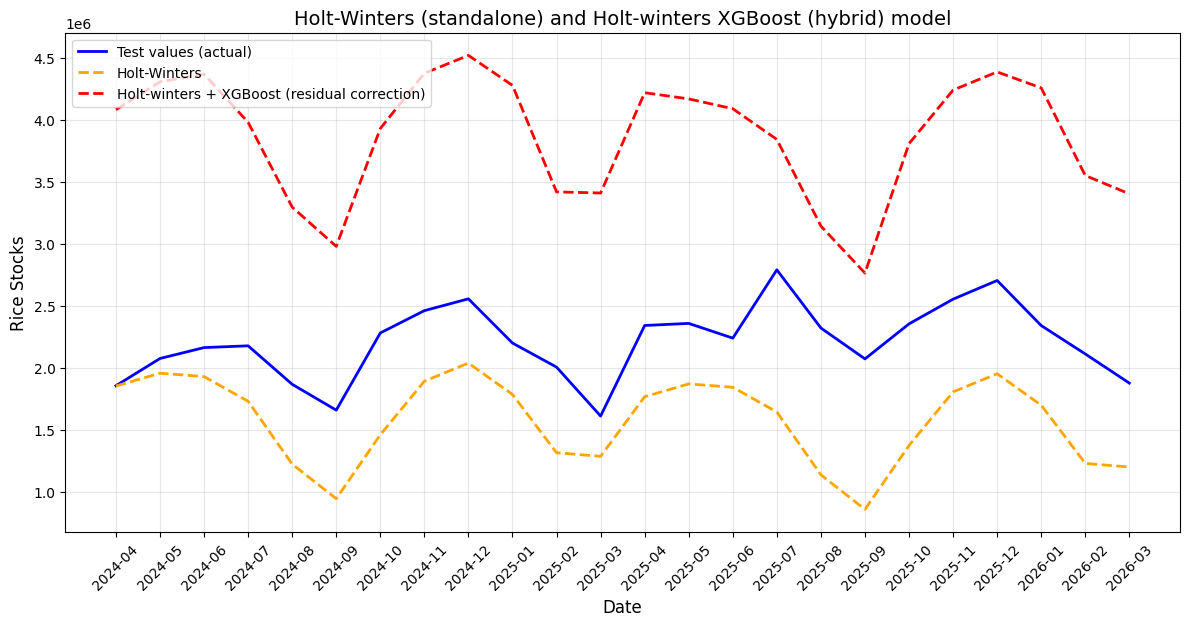

In [183]:
# 1. Formatting the date range for the legend
start_date = data['date'].iloc[-holdout_size:].min()
end_date = data['date'].iloc[-holdout_size:].max()
date_range_str = f"({start_date} to {end_date})"

# 2. Plotting
plt.figure(figsize=(12, 6))

# Actual Values
plt.plot(data['date'].iloc[-holdout_size:], test, label=f'Test values (actual)', color='blue', linewidth=2)

# Holt-winters standalone
plt.plot(data['date'].iloc[-holdout_size:], final_forecast, label=f'Holt-Winters', color='orange', linestyle='--', linewidth=2)

# Predicted Values
plt.plot(data['date'].iloc[-holdout_size:], final_hybrid_forecast, label=f'Holt-winters + XGBoost (residual correction)', color='red', linestyle='--', linewidth=2)

# 3. Aesthetics
plt.title('Holt-Winters (standalone) and Holt-winters XGBoost (hybrid) model', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice Stocks', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(data['date'][::1].iloc[-holdout_size:], rotation=45)

plt.show()

In [184]:
hybrid_mape = mean_absolute_percentage_error(test, final_hybrid_forecast)
hybrid_mae = mean_absolute_error(test, final_hybrid_forecast)
hybrid_rmse = root_mean_squared_error(test, final_hybrid_forecast)
hybrid_r2 = r2_score(test, final_hybrid_forecast)

print(f"Final Hybrid Model MAPE {round(hybrid_mape, 4)}\n"
f"Final Model MAE: {round(hybrid_mae, 4)}\n"
f"Final Model RMSE: {round(hybrid_rmse, 4)}\n"
f"Final Model R2: {round(hybrid_r2, 4)}")

Final Hybrid Model MAPE 0.7659
Final Model MAE: 1659425.3428
Final Model RMSE: 1706881.4771
Final Model R2: -32.5351


### XGBoost standalone

In [97]:
xgb = total_stock

X_train = xgb.drop(columns=['stock_total']).iloc[:-holdout_size]
y_train = xgb['stock_total'].iloc[:-holdout_size]

# xgb_test = xgb.drop(columns=['stock_total']).iloc[-24:]

In [98]:
X_train['is_lean_month'] = X_train.is_lean_month.astype('int')

In [99]:
# X_ext is your dataframe of external features
grid_search.fit(X_train, y_train)

# The 'best_model' now contains the XGBoost model trained on the WHOLE dataset
best_xgb_model = grid_search.best_estimator_

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [11:35:53] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "early_stopping", "subsample:" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [185]:
xgb_test_data[-holdout_size:]

,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,is_lean_month
date,,,,,,,,
2024-04,1015289.61,728730.70,99033.00,36.66,39.79,40.31,44.53,0
2024-05,993969.74,787970.99,100117.00,36.96,40.12,40.62,44.78,0
2024-06,884995.00,848107.90,85102.00,37.24,40.34,40.89,44.99,0
2024-07,758563.57,984761.41,60844.00,37.89,41.13,41.23,45.32,1
2024-08,636406.24,945096.67,50948.00,41.91,45.68,43.29,47.65,1
2024-09,600168.08,902290.44,43636.00,43.05,46.75,47.54,52.69,1
2024-10,917842.92,1080905.36,44240.00,42.56,46.20,45.42,50.99,0
2024-11,1017221.98,901106.38,60230.00,43.88,47.31,46.73,51.99,0
2024-12,986776.75,851875.81,57130.00,45.83,49.11,48.48,53.82,0


In [186]:
xgb_test_data['is_lean_month'] = xgb_test_data.is_lean_month.astype('int')
xgb_model = best_xgb_model.predict(xgb_test_data[-24:])

In [188]:
remaining_features = remaining_features.drop(columns=['stock_total'])
remaining_features = add_lean_months(remaining_features)

In [206]:
xgb_future = best_xgb_model.predict(fut.drop(columns=['date']))

In [205]:
fut = pd.concat([xgb_test_data, remaining_features], axis=0)
fut['date'] = fut.index.astype(str)
fut

,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,is_lean_month,date
date,,,,,,,,,
2024-04,1015289.61,728730.70,99033.00,36.66,39.79,40.31,44.53,0,2024-04
2024-05,993969.74,787970.99,100117.00,36.96,40.12,40.62,44.78,0,2024-05
2024-06,884995.00,848107.90,85102.00,37.24,40.34,40.89,44.99,0,2024-06
2024-07,758563.57,984761.41,60844.00,37.89,41.13,41.23,45.32,1,2024-07
2024-08,636406.24,945096.67,50948.00,41.91,45.68,43.29,47.65,1,2024-08
2024-09,600168.08,902290.44,43636.00,43.05,46.75,47.54,52.69,1,2024-09
2024-10,917842.92,1080905.36,44240.00,42.56,46.20,45.42,50.99,0,2024-10
2024-11,1017221.98,901106.38,60230.00,43.88,47.31,46.73,51.99,0,2024-11
2024-12,986776.75,851875.81,57130.00,45.83,49.11,48.48,53.82,0,2024-12


In [193]:
remaining_features['date'] = remaining_features.index.astype(str)
future_pred = pd.concat([data, remaining_features], axis=0)
future_pred

,date,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,is_lean_month
date,,,,,,,,,,
2000-01,2000-01,2364500.0,1149700.00,488200.00,726600.00,15.65,17.38,17.05,19.00,0
2000-02,2000-02,2042300.0,1009500.00,420600.00,612200.00,15.83,17.57,17.20,19.12,0
2000-03,2000-03,1765700.0,832200.00,381000.00,552500.00,15.98,17.64,17.32,19.22,0
2000-04,2000-04,1874900.0,954400.00,441200.00,479300.00,16.05,17.62,17.38,19.21,0
2000-05,2000-05,2067000.0,1059500.00,509600.00,497900.00,16.29,17.75,17.45,19.27,0
...,...,...,...,...,...,...,...,...,...,...
2026-11,2026-11,NaN,1149260.99,944142.43,460735.00,35.65,40.28,40.29,46.80,0
2026-12,2026-12,NaN,1026400.66,1221968.35,456138.00,37.83,42.94,41.49,48.25,0
2027-01,2027-01,NaN,1043525.46,858877.00,438752.60,39.81,45.16,43.29,50.05,0


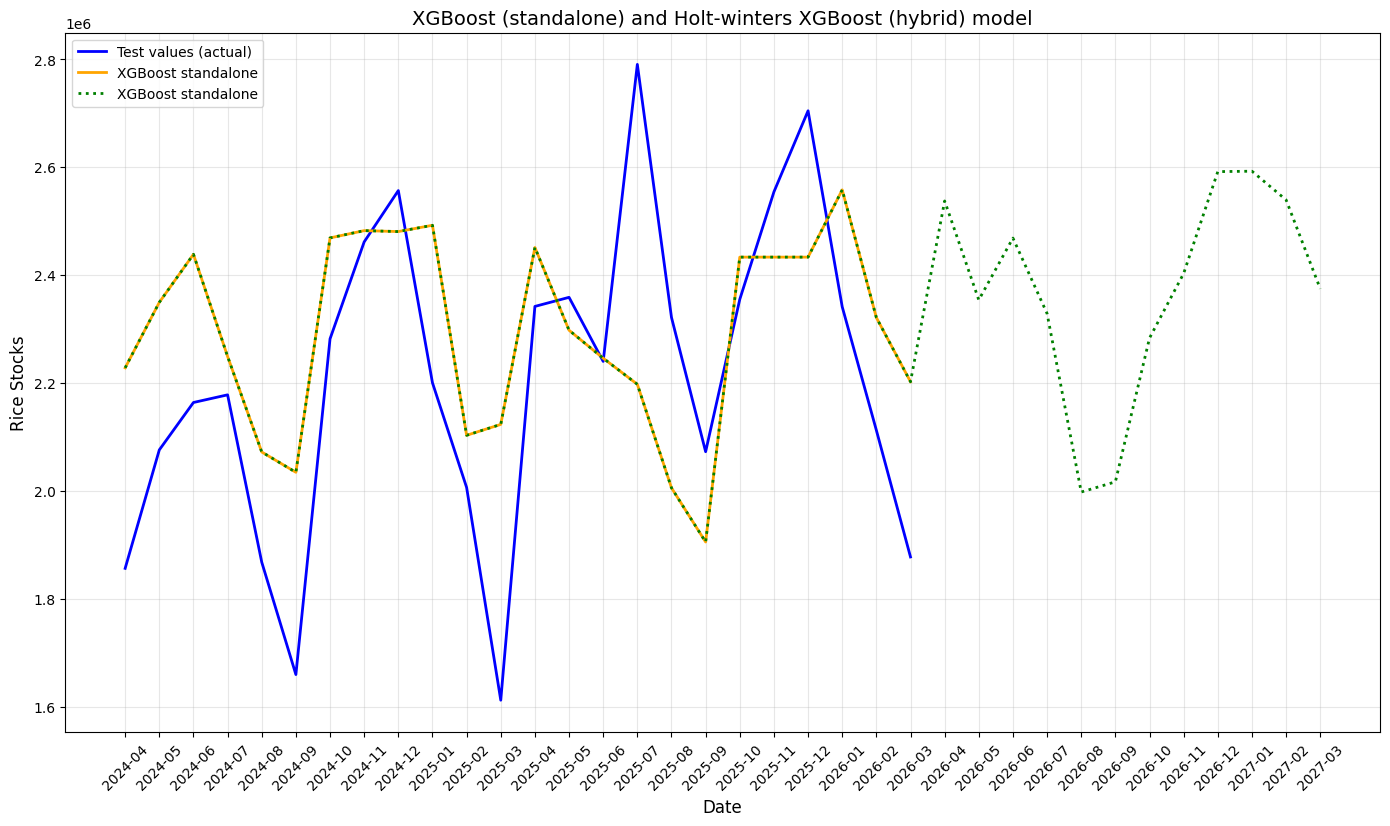

In [249]:
# 1. Formatting the date range for the legend
# start_date = data['date'].iloc[-holdout_size:].min()
# end_date = data['date'].iloc[-holdout_size:].max()
start_date = total_stock.index[-holdout_size:].min()
end_date = future_pred.max()
date_range_str = f"({start_date} to {end_date})"

# 2. Plotting
plt.figure(figsize=(14, 8))

# Actual Values
plt.plot(data['date'].iloc[-holdout_size:], test, label=f'Test values (actual)', color='blue', linewidth=2)

# Holt-winters standalone
plt.plot(data['date'].iloc[-holdout_size:], xgb_model, label=f'XGBoost standalone', color='orange', linestyle='-', linewidth=2)

# # Holt-Winters and XGBoost Values
# plt.plot(data['date'].iloc[-holdout_size:], final_hybrid_forecast, label=f'Holt-winters + XGBoost (residual correction)', color='red', linestyle='--', linewidth=2)

# Holt-winters standalone
plt.plot(future_pred['date'].iloc[-36:], xgb_future, label=f'XGBoost standalone', color='green', linestyle=':', linewidth=2)

# 3. Aesthetics
plt.title('XGBoost (standalone) and Holt-winters XGBoost (hybrid) model', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice Stocks', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(future_pred['date'][::1].iloc[-36:], rotation=45)

plt.show()

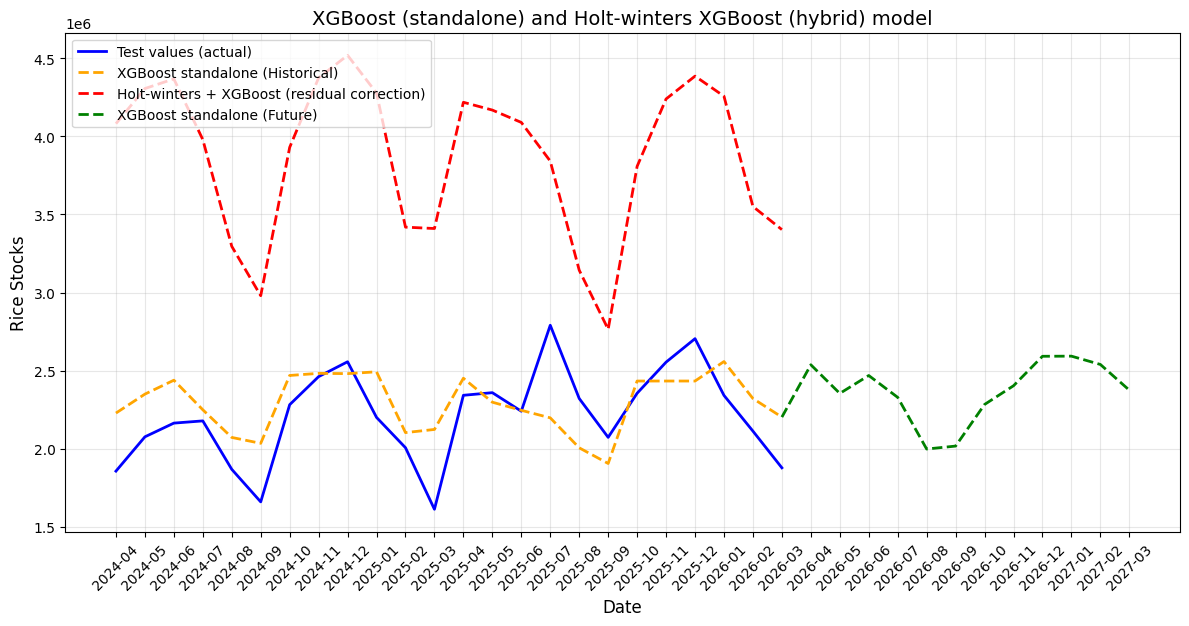

In [229]:
import pandas as pd

start_date = total_stock.index[-holdout_size:].min()
end_date = future_pred.max()
date_range_str = f"({start_date} to {end_date})"

# ==========================================================
# 1. BRIDGE THE GAP (Connecting Orange to Green)
# ==========================================================
# Get the exact handoff date (last date of the historical/test set)
handoff_date = data['date'].iloc[-1]

# Extract the last predicted value from the historical XGBoost model (Orange line's end)
last_xgb_pred = xgb_model.iloc[-1] if hasattr(xgb_model, 'iloc') else xgb_model[-1]

# Prepend that handoff point to your future data arrays
future_dates_connected = pd.concat([pd.Series([handoff_date]), future_pred['date'].iloc[-12:]])
future_vals_connected = pd.concat([pd.Series([last_xgb_pred]), pd.Series(xgb_future).iloc[-12:]])

# 2. Plotting
plt.figure(figsize=(12, 6))

# Actual Values
plt.plot(data['date'].iloc[-holdout_size:], test, label='Test values (actual)', color='blue', linewidth=2)

# Holt-winters standalone (Orange Line)
plt.plot(data['date'].iloc[-holdout_size:], xgb_model, label='XGBoost standalone (Historical)', color='orange', linestyle='--', linewidth=2)

# Holt-Winters and XGBoost Values
plt.plot(data['date'].iloc[-holdout_size:], final_hybrid_forecast, label='Holt-winters + XGBoost (residual correction)', color='red', linestyle='--', linewidth=2)

# ==========================================================
# UPDATED: Green line now starts precisely where the Orange line ended
# ==========================================================
plt.plot(future_dates_connected, future_vals_connected, label='XGBoost standalone (Future)', color='green', linestyle='--', linewidth=2)

# 3. Aesthetics
plt.title('XGBoost (standalone) and Holt-winters XGBoost (hybrid) model', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice Stocks', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(future_pred['date'][::1].iloc[-36:], rotation=45)

plt.show()

In [230]:
hybrid_mape = mean_absolute_percentage_error(test, xgb_model)
hybrid_mae = mean_absolute_error(test, xgb_model)
hybrid_rmse = root_mean_squared_error(test, xgb_model)
hybrid_r2 = r2_score(test, xgb_model)

print(f"Final Model MAPE {round(hybrid_mape, 4)}\n"
f"Final Model MAE: {round(hybrid_mae, 4)}\n"
f"Final Model RMSE: {round(hybrid_rmse, 4)}\n"
f"Final Model R2: {round(hybrid_r2, 4)}")

Final Model MAPE 0.104
Final Model MAE: 217858.4765
Final Model RMSE: 262940.416
Final Model R2: 0.2042


## Features to be added


### eval metrics

In [ ]:
metrics_dict = {
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [0.85, 0.96],
    "F1-Score": [0.84, 0.96]
}

df = pd.DataFrame(metrics_dict)

# Print standard clean table
print(df.to_string(index=False))

# OR Print as a Markdown table for your docs/reports
print("\n--- Markdown Format ---")
print(df.to_markdown(index=False))

### lag values

In [ ]:
df = pd.DataFrame({'sales': [10, 15, 20, 25, 30, 35]})

# Creating lags
df['lag_1'] = df['sales'].shift(1, freq='D')
df['lag_2'] = df['sales'].shift(2)
# df['lag_7'] = df['sales'].shift(7) # Useful for weekly seasonality

print(df)

NotImplementedError: This method is only implemented for DatetimeIndex, PeriodIndex and TimedeltaIndex; Got type RangeIndex

In [ ]:
df = pd.DataFrame(
    [[10, 13, 17], [20, 23, 27], [15, 18, 22], [30, 33, 37], [45, 48, 52]],
    columns=["Col1", "Col2", "Col3"],
    index=pd.date_range("2020-01-01", "2020-01-05"))
df

,Col1,Col2,Col3
2020-01-01,10,13,17
2020-01-02,20,23,27
2020-01-03,15,18,22
2020-01-04,30,33,37
2020-01-05,45,48,52


In [ ]:
df.shift(periods=3, freq="infer")

,Col1,Col2,Col3
2020-01-04,10,13,17
2020-01-05,20,23,27
2020-01-06,15,18,22
2020-01-07,30,33,37
2020-01-08,45,48,52


In [ ]:
test = data_xgb[['date', 'stock_household']]
test.index = pd.to_datetime(test['date']).dt.to_period('M')
test = test.drop(columns=['date'])

# test.shift(periods=3, freq="infer")
# test['stock_household_lag_1'] = test['stock_household'].shift(1, freq='M')
test_new = test['stock_household'].shift(3, freq='M')
test_new = pd.DataFrame(test_new)
test_new.rename(columns={'stock_household' : 'stock_household_lag'}, inplace=True)

new = pd.concat([test, test_new], axis=1)
new


,stock_household,stock_household_lag
date,,
2000-01,1149700.00,NaN
2000-02,1009500.00,NaN
2000-03,832200.00,NaN
2000-04,954400.00,1149700.00
2000-05,1059500.00,1009500.00
...,...,...
2024-02,685199.12,1017221.98
2024-03,694618.06,986776.75
2024-04,NaN,1000502.23


In [ ]:
new_data = data.drop(columns=['stock_total', 'is_lean_month', 'month'])
new_data.index = pd.to_datetime(data['date']).dt.to_period('M')
new_data = new_data.drop(columns=['date'])

new_data = new_data.shift(periods=6, freq="infer")
# new_data = pd.concat([new_data, data['stock_total']], axis=1)
# new_data = pd.concat([data['stock_total'], new_data], axis=1)
stock_total = data[['date', 'stock_total']]
stock_total.index = pd.to_datetime(stock_total['date']).dt.to_period('M')
stock_total = stock_total.drop(columns=['date'])

new_data = pd.concat([stock_total, new_data], axis=1)
new_data

,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price
date,,,,,,,,
2000-01,2364500.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-02,2042300.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-03,1765700.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-04,1874900.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-05,2067000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
2026-05,NaN,1149260.99,944142.43,460735.00,35.65,40.28,40.29,46.80
2026-06,NaN,1026400.66,1221968.35,456138.00,37.83,42.94,41.49,48.25
2026-07,NaN,1043525.46,858877.00,438752.60,39.81,45.16,43.29,50.05


### display all data values

In [ ]:
with pd.option_context('display.max_rows', None, 'display.max_columns', None):  # more options can be specified also
    print(new_data[-6:])

         stock_total  stock_household  stock_commercial  stock_nfa  \
date                                                                 
2026-04          NaN        952087.39         954908.93  447900.00   
2026-05          NaN       1149260.99         944142.43  460735.00   
2026-06          NaN       1026400.66        1221968.35  456138.00   
2026-07          NaN       1043525.46         858877.00  438752.60   
2026-08          NaN        899568.63         791200.85  421512.67   
2026-09          NaN        908721.92         564220.75  404386.21   

         regular_wholesale_price  milled_wholesale_price  \
date                                                       
2026-04                    34.68                   39.48   
2026-05                    35.65                   40.28   
2026-06                    37.83                   42.94   
2026-07                    39.81                   45.16   
2026-08                    41.60                   47.72   
2026-09            

In [ ]:
def lean(dataset):
  lean = set([7, 8, 9])
  dataset['is_lean_month'] = np.where(dataset.index.month.isin(lean), '1', '0')
  return dataset

### Save the model

In [ ]:
import joblib

# 1. Save the model to a file
model_filename = ""
joblib.dump(final_model, model_filename)
print(f"Model saved successfully as {model_filename}")

# --- Later, in a different script or session ---

# 2. Load the model
loaded_model = joblib.load(model_filename)

# 3. Predict the next 12 months (out-of-sample)
# Note: This doesn't require the training data to be present!
future_forecast = loaded_model.forecast(12)
print("\nFuture 12-Month Forecast:")
print(future_forecast)

### add loss curve

In [ ]:
from sklearn.model_selection import GridSearchCV, train_test_split
# Generate dummy data: 1000 rows, 5 features
np.random.seed(42)
X = np.random.rand(1000, 5)
# Target is a combination of features + noise
y = (X[:, 0] * 2) + (X[:, 1] ** 2) - (X[:, 2] * 1.5) + np.random.normal(0, 0.1, 1000)

# Step 1: Split into Train (70%) and Temp (30%)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)

# Step 2: Split Temp into Validation (15%) and Test (15%)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

In [ ]:
# Initialize the model
xgb_model = XGBRegressor(n_estimators=100, objective='reg:squarederror')

# Define parameters to test
param_grid = {
    'learning_rate': [0.01, 0.02, 0.05, 0.1, 0.3, 0.5],
    'max_depth': [3, 5, 7, 9, 10]
}

# Setup GridSearchCV
grid = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    cv=6,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

# Fit using the validation set for the loss curve
grid.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    # eval_metric="rmse",
    verbose=False
)

GridSearchCV(cv=6,
             estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=False, eval_metric=None,
                                    feature_types=None, feature_weights=None,
                                    gamma=None, grow_policy=None,
                                    importance_type=None,
                                    interaction_constraints=None...
                                    max_cat_threshold=None,
                                    max_cat_to_onehot=None, max_delta_step=None,
                                    max_depth=None, max_leaves=None,
                                    min_child_weight=None, missing=nan,
                                    monotone_constraints=None,
                                    multi_strategy=None, n_estimators=100,
                                    n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'learning_rate': [0.01, 0.02, 0.05, 0.1, 0.3, 0.5],
                         'max_depth': [3, 5, 7, 9, 10]},
             scoring='neg_mean_squared_error')

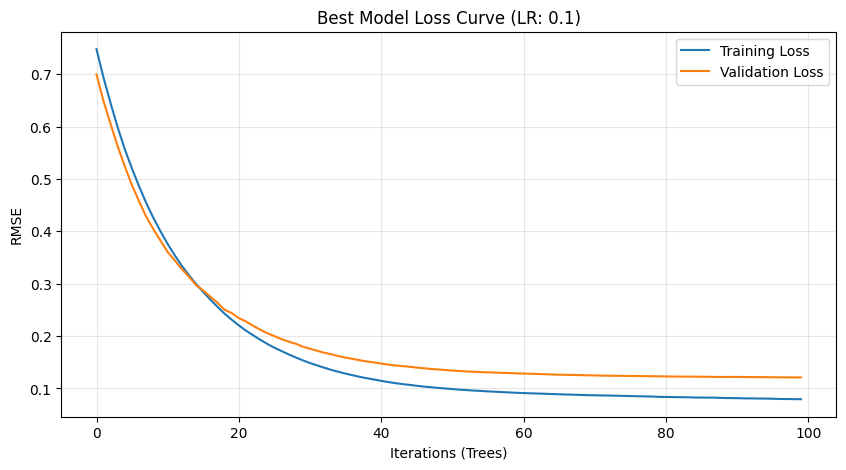

In [ ]:
# Extract evaluation results from the BEST estimator
results = grid.best_estimator_.evals_result()

plt.figure(figsize=(10, 5))
plt.plot(results['validation_0']['rmse'], label='Training Loss')
plt.plot(results['validation_1']['rmse'], label='Validation Loss')
plt.title(f"Best Model Loss Curve (LR: {grid.best_params_['learning_rate']})")
plt.xlabel("Iterations (Trees)")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

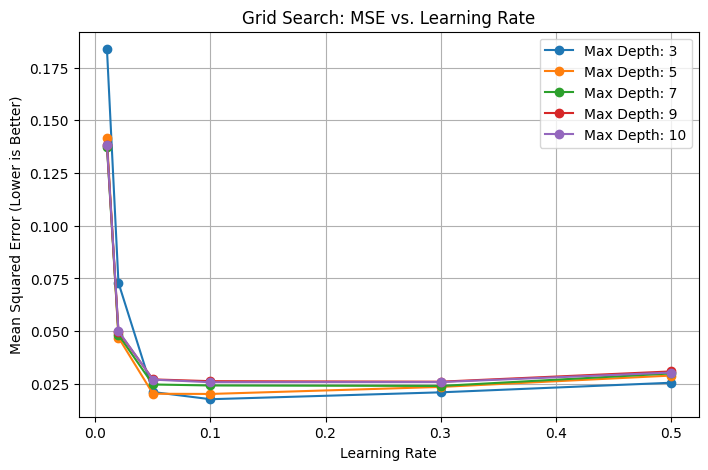

In [ ]:
cv_results = pd.DataFrame(grid.cv_results_)

# Plotting performance vs Learning Rate
plt.figure(figsize=(8, 5))
for depth in param_grid['max_depth']:
    subset = cv_results[cv_results['param_max_depth'] == depth]
    plt.plot(subset['param_learning_rate'], -subset['mean_test_score'], marker='o', label=f'Max Depth: {depth}')

plt.title("Grid Search: MSE vs. Learning Rate")
plt.xlabel("Learning Rate")
plt.ylabel("Mean Squared Error (Lower is Better)")
plt.legend()
plt.grid(True)
plt.show()